# Titanic - Machine Learning from Disaster




### 1. Data Loading

First, let's load the Titanic dataset. The dataset is split into training and testing sets. We will define a function to download and load the data into pandas DataFrames.

In [1]:
from pathlib import Path
import pandas as pd
import tarfile
import urllib.request

def load_titanic_data():
    tarball_path = Path("datasets/titanic.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/titanic.tgz"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as titanic_tarball:
            titanic_tarball.extractall(path="datasets", filter="data")
    return [pd.read_csv(Path("datasets/titanic") / filename)
            for filename in ("train.csv", "test.csv")]

Now, let's call the `load_titanic_data()` function to get our `train_data` and `test_data` DataFrames.

In [2]:
train_data, test_data=load_titanic_data()

### 2. Initial Data Exploration

Let's start by looking at the first few rows of the training data to understand its structure and content.

In [5]:
train_data.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


We'll set `PassengerId` as the index for both training and testing datasets.

In [6]:
train_data=train_data.set_index('PassengerId')
test_data=test_data.set_index('PassengerId')

Let's get a concise summary of the training data, including the data types and non-null values for each column. This helps in identifying missing values and understanding the data structure.

In [7]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    object 
 3   Sex       891 non-null    object 
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    object 
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    object 
 10  Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 83.5+ KB


To get a better sense of the distribution of age for different genders, let's look at the median age of female passengers.

In [8]:
train_data[train_data['Sex']=='female']['Age'].median()

27.0

We can get a statistical summary of the numerical columns in the training data using the `.describe()` method.

In [9]:
train_data.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699113,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526507,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.416700,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


The target variable in this dataset is `Survived`. Let's check the count of survivors 1 and non-survivors 0 to understand the class distribution.

In [64]:
train_data['Survived'].value_counts()

,count
Survived,
0,549
1,342


Let's further explore the categorical attributes to understand their distributions.

Let's examine the distribution of `Pclass` (passenger class).

In [11]:
train_data['Pclass'].value_counts()

,count
Pclass,
3,491
1,216
2,184


Now, let's look at the distribution of `Sex`.

In [12]:
train_data['Sex'].value_counts()

,count
Sex,
male,577
female,314


Finally, let's check the distribution of `Embarked` (port of embarkation).

In [13]:
train_data['Embarked'].value_counts()

,count
Embarked,
S,644
C,168
Q,77


### 3. Build Preprocessing Pipelines

Before training a model, we need to preprocess the data. This involves handling missing values, scaling numerical features, and encoding categorical features. We'll build separate pipelines for numerical and categorical attributes and then combine them using `ColumnTransformer`.

#### Numerical Pipeline

For numerical features, we'll use a `SimpleImputer` to fill missing values with the median, and then a `StandardScaler` to scale the features.

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
     ('scaler',StandardScaler())
])

#### Categorical Pipeline

For categorical features, we'll use a `SimpleImputer` to fill missing values with the most frequent value, and then `OneHotEncoder` to convert them into numerical representations.

In [15]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

cat_pipeline=Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("cat_encoder", OneHotEncoder(sparse_output=False,handle_unknown='ignore')),
    ])

#### Combined Preprocessing Pipeline

We combine the numerical and categorical pipelines using `ColumnTransformer`. We define the numerical and categorical attributes that will be processed by their respective pipelines.

In [16]:
from sklearn.compose import ColumnTransformer

num_attribs=["Age","SibSp","Parch","Fare"]
cat_attribs=["Pclass","Sex","Embarked"]

preprocess_pipeline=ColumnTransformer([
    ("num",num_pipeline,num_attribs),
    ("cat",cat_pipeline,cat_attribs),
])

### 4. Model Training (Initial Attempt)

Now, let's apply the preprocessing pipeline to our training data and then train a `RandomForestClassifier`.

In [17]:
X_train=preprocess_pipeline.fit_transform(train_data)
X_train

array([[-0.56573582,  0.43279337, -0.47367361, ...,  0.        ,
         0.        ,  1.        ],
       [ 0.6638609 ,  0.43279337, -0.47367361, ...,  1.        ,
         0.        ,  0.        ],
       [-0.25833664, -0.4745452 , -0.47367361, ...,  0.        ,
         0.        ,  1.        ],
       ...,
       [-0.10463705,  0.43279337,  2.00893337, ...,  0.        ,
         0.        ,  1.        ],
       [-0.25833664, -0.4745452 , -0.47367361, ...,  1.        ,
         0.        ,  0.        ],
       [ 0.20276213, -0.4745452 , -0.47367361, ...,  0.        ,
         1.        ,  0.        ]])

We extract the target variable `Survived` for training.

In [18]:
y_train=train_data['Survived']

#### Random Forest Classifier

Let's train a `RandomForestClassifier` with default parameters and evaluate its performance using cross-validation.

First, we initialize and fit the `RandomForestClassifier` to our preprocessed training data.

In [19]:
from sklearn.ensemble import RandomForestClassifier

forest_clf=RandomForestClassifier(n_estimators=100, random_state=42)
forest_clf.fit(X_train,y_train)

RandomForestClassifier(random_state=42)

Now, we preprocess the `test_data` using the same pipeline and make predictions.

In [20]:
X_test=preprocess_pipeline.transform(test_data)
y_pred=forest_clf.predict(X_test)

To get a more robust estimate of our model's performance, we'll use 10-fold cross-validation on the training data.

In [21]:
from sklearn.model_selection import cross_val_score

forest_scores=cross_val_score(forest_clf,X_train,y_train,cv=10)
forest_scores.mean()

np.float64(0.8137578027465668)

#### Support Vector Machine (SVM) Classifier

Let's try another classifier, a Support Vector Machine (SVC), to see if we can achieve better performance.

We initialize an SVC and evaluate its performance using 10-fold cross-validation, similar to the Random Forest classifier.

In [22]:
from sklearn.svm import SVC

svm_clf=SVC(gamma="auto")
svm_scores=cross_val_score(svm_clf,X_train,y_train,cv=10)
svm_scores.mean()

np.float64(0.8249313358302123)

The SVM classifier shows a slightly better average accuracy than the Random Forest classifier in this initial comparison.

To visualize the performance comparison between the SVM and Random Forest models, let's create a box plot of their cross-validation scores.

/tmp/ipython-input-1820570224.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([svm_scores,forest_scores],labels=("SVM","Random Forest"))


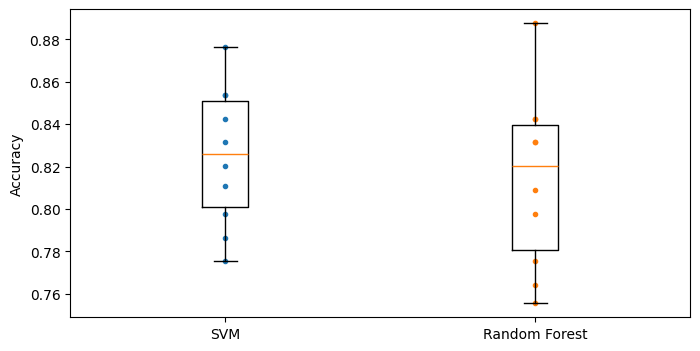

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.plot([1]*10,svm_scores,".")
plt.plot([2]*10,forest_scores,".")
plt.boxplot([svm_scores,forest_scores],labels=("SVM","Random Forest"))
plt.ylabel("Accuracy")
plt.show()

### 5. Feature Engineering and Improvement

Now, let's try to improve our model's performance by creating new features from the existing ones. We'll start by categorizing `Age` into `AgeBucket` and combining `SibSp` and `Parch` into `RelativesOnboard`.

Let's create an `AgeBucket` feature by grouping ages into 15-year intervals and observe the survival rate within each bucket.

In [24]:
train_data["AgeBucket"]=train_data["Age"]//15*15
train_data[["AgeBucket","Survived"]].groupby(["AgeBucket"]).mean()

,Survived
AgeBucket,
0.0,0.576923
15.0,0.362745
30.0,0.423256
45.0,0.404494
60.0,0.240000
75.0,1.000000


Next, let's create a `RelativesOnboard` feature by summing `SibSp` (siblings/spouses aboard) and `Parch` (parents/children aboard), and then analyze its relationship with survival.

In [25]:
train_data["RelativesOnboard"]=train_data['SibSp']+train_data['Parch']
train_data[["RelativesOnboard","Survived"]].groupby(
["RelativesOnboard"]).mean()

,Survived
RelativesOnboard,
0,0.303538
1,0.552795
2,0.578431
3,0.724138
4,0.200000
5,0.136364
6,0.333333
7,0.000000
10,0.000000


Let's check the updated information of the training data after adding the new features.

In [26]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Survived          891 non-null    int64  
 1   Pclass            891 non-null    int64  
 2   Name              891 non-null    object 
 3   Sex               891 non-null    object 
 4   Age               714 non-null    float64
 5   SibSp             891 non-null    int64  
 6   Parch             891 non-null    int64  
 7   Ticket            891 non-null    object 
 8   Fare              891 non-null    float64
 9   Cabin             204 non-null    object 
 10  Embarked          889 non-null    object 
 11  AgeBucket         714 non-null    float64
 12  RelativesOnboard  891 non-null    int64  
dtypes: float64(3), int64(5), object(5)
memory usage: 97.5+ KB


### 6. Advanced Preprocessing Pipeline with New Features

With our new features (`RelativesOnboard` and `AgeBucket`), we need to update our preprocessing pipeline to include them. We'll also adjust the numerical and categorical attributes accordingly.

We'll redefine `num_attribs` and `cat_attribs` to include our engineered features and then create a new `preprocess_pipeline_advanced`.

In [27]:
from sklearn.compose import ColumnTransformer

num_attribs=["RelativesOnboard","Fare"]
cat_attribs=["Pclass","Sex","AgeBucket","Embarked"]

preprocess_pipeline_advanced=ColumnTransformer([
    ("num",num_pipeline,num_attribs),
    ("cat",cat_pipeline,cat_attribs),
])

Let's apply this advanced preprocessing pipeline, train a `RandomForestClassifier` again, and evaluate its performance.

In [28]:
X_train = preprocess_pipeline_advanced.fit_transform(train_data)
y_train = train_data['Survived']

from sklearn.ensemble import RandomForestClassifier

forest_clf = RandomForestClassifier(n_estimators=200, random_state=42)
forest_clf.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

Before making predictions on the test set, we need to apply the same feature engineering and imputation steps to the `test_data` to ensure consistency.

In [29]:
test_data["Age"].fillna(train_data["Age"].median(), inplace=True)
test_data["Fare"].fillna(train_data["Fare"].median(), inplace=True)

/tmp/ipython-input-680629632.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  test_data["Age"].fillna(train_data["Age"].median(), inplace=True)
/tmp/ipython-input-680629632.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace

Now we can create the new features for the `test_data`.

In [30]:
test_data["RelativesOnboard"] = test_data["SibSp"] + test_data["Parch"]
test_data["AgeBucket"] = test_data["Age"] // 15*15

Finally, we preprocess the `test_data` with the advanced pipeline and make predictions using the trained Random Forest classifier.

In [31]:
X_test = preprocess_pipeline_advanced.transform(test_data)
predictions = forest_clf.predict(X_test)

Let's re-evaluate the Random Forest classifier with the advanced features using cross-validation.

In [32]:
forest_scores=cross_val_score(forest_clf,X_train,y_train,cv=10)
forest_scores.mean()

np.float64(0.8126092384519351)

The previous attempt at improving the model with `AgeBucket` and `RelativesOnboard` did not yield a better cross-validation score. This suggests that simple feature engineering might not be enough, or that the current hyperparameters for the Random Forest are not optimal.

To systematically find the best hyperparameters, we will use **Grid Search**.

### 7. Automating Preprocessing and Model Training with a Full Pipeline

To make our workflow more robust and reproducible, we can create a single `Pipeline` that includes both feature engineering, preprocessing, and the classifier. This allows us to treat the entire process as one single model.

We define a `FunctionTransformer` to apply our feature engineering steps (`add_features`) and then combine it with the advanced preprocessor and a Random Forest classifier into a `full_pipeline`.

In [33]:
from sklearn.preprocessing import FunctionTransformer

def add_features(df):
    df = df.copy()
    df["RelativesOnboard"] = df["SibSp"] + df["Parch"]
    df["AgeBucket"] = df["Age"] // 15
    return df

feature_adder = FunctionTransformer(add_features)

full_pipeline = Pipeline([
    ("feature_adder", feature_adder),
    ("preprocessor", preprocess_pipeline_advanced),
    ("classifier", RandomForestClassifier(n_estimators=200, random_state=42))
])

Now, we can fit this `full_pipeline` to the original training data and make predictions on the test data.

In [34]:
full_pipeline.fit(train_data, train_data["Survived"])
predictions = full_pipeline.predict(test_data)

### 8. Hyperparameter Tuning with GridSearchCV

Grid Search is a powerful technique to find the best hyperparameters for a model. We'll use `GridSearchCV` to systematically search through a predefined set of hyperparameters for our Random Forest classifier within the preprocessing pipeline.

First, let's define a `full_pipeline` without the `feature_adder` as we will apply the feature engineering directly on the data when fitting `GridSearchCV` for simplicity in this step. The features `RelativesOnboard` and `AgeBucket` will be included in the `preprocess_pipeline_advanced`.

In [35]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

full_pipeline = Pipeline([
    ("preprocessor", preprocess_pipeline_advanced),
    ("clf", RandomForestClassifier(random_state=42))
])

Now, we define the `param_grid` which contains the hyperparameters we want to tune for our `RandomForestClassifier`. We then initialize `GridSearchCV` with our pipeline, parameter grid, and cross-validation settings, and fit it to the training data.

In [36]:
param_grid = {
    "clf__n_estimators": [100, 200, 500],
    "clf__max_depth": [None, 5, 10, 15, 20],
    "clf__min_samples_split": [2, 5, 10],
    "clf__min_samples_leaf": [1, 2, 4],
    "clf__max_features": ["sqrt", "log2"]
}

from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    full_pipeline,
    param_grid,
    cv=5,               # 5-fold cross-validation
    scoring="accuracy",
)

grid_search.fit(train_data, train_data["Survived"])

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['RelativesOnboard',
                                                                          'Fare']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('cat_encoder',
                                                                                          OneHotEncoder(handle_unknown='ignore',
                                                                                                        sparse_output=False))]),
                                                                         ['Pclass',
                                                                          'Sex',
                                                                          'AgeBucket',
                                                                          'Embarked'])])),
                                       ('clf',
                                        RandomForestClassifier(random_state=42))]),
             param_grid={'clf__max_depth': [None, 5, 10, 15, 20],
                         'clf__max_features': ['sqrt', 'log2'],
                         'clf__min_samples_leaf': [1, 2, 4],
                         'clf__min_samples_split': [2, 5, 10],
                         'clf__n_estimators': [100, 200, 500]},
             scoring='accuracy')

After running the grid search, we can retrieve the best combination of hyperparameters found.

In [37]:
grid_search.best_params_

{'clf__max_depth': 10,
 'clf__max_features': 'sqrt',
 'clf__min_samples_leaf': 1,
 'clf__min_samples_split': 10,
 'clf__n_estimators': 200}

We can also get the best estimator (the model with the best hyperparameters) directly from `grid_search`.

In [38]:
best_model=grid_search.best_estimator_
best_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['RelativesOnboard', 'Fare']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('cat_encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['Pclass', 'Sex', 'AgeBucket',
                                                   'Embarked'])])),
                ('clf',
                 RandomForestClassifier(max_depth=10, min_samples_split=10,
                                        n_estimators=200, random_state=42))])

Assign the best estimator to `best_model`.

In [39]:
best_model=grid_search.best_estimator_

Let's evaluate the `best_model` using cross-validation to get an unbiased estimate of its performance on unseen data.

In [40]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(best_model, train_data, train_data["Survived"], cv=5)
print(scores)
print(scores.mean())

[0.82681564 0.81460674 0.85955056 0.80898876 0.84831461]
0.8316552633230808


The average cross-validation score indicates that the grid search improved our model's performance. Now, we will consider further improvements by refining our feature engineering, especially focusing on `Cabin` and `Fare`.

### 9. Advanced Feature Engineering on `Cabin` and `Fare`

Let's create a more sophisticated feature engineering function that handles missing values, creates `RelativesOnboard` and `AgeBucket`, and introduces new features like `LogFare` (log-transformed Fare) and `Deck` (extracted from Cabin).

We define `create_advanced_features` to perform these transformations. This function will be applied to both training and testing datasets. We also separate `X_train` and `y_train` from the transformed training data.

In [41]:
# Let's create an advcanced features function from scratch
import numpy as np

def create_advanced_features(df):
    df_new = df.copy()

    # Fill the empty ones with median
    df_new['Age'] = df_new['Age'].fillna(df['Age'].median())
    df_new['Fare'] = df_new['Fare'].fillna(df['Fare'].median())
    df_new['Embarked'] = df_new['Embarked'].fillna(df['Embarked'].mode()[0])

    # Like previously
    df_new["RelativesOnboard"] = df_new['SibSp'] + df_new['Parch']
    df_new['AgeBucket']=df['Age']//15

    # We use log in order to have a gaussian feature
    df_new['LogFare'] = np.log1p(df_new['Fare'])

    # The new feature for better classification
    df_new['Deck'] = df_new['Cabin'].str[0].fillna('U')

    return df_new

train_data_fe = create_advanced_features(train_data)
test_data_fe = create_advanced_features(test_data)

X_train = train_data_fe.drop("Survived", axis=1)
y_train = train_data_fe["Survived"]

### 10. Refined Preprocessing Pipeline with Advanced Features

With the newly engineered features, we need to update our preprocessing pipelines to incorporate `LogFare` and `Deck`. The numerical pipeline will now include `RelativesOnboard` and `LogFare`, and the categorical pipeline will include `Pclass`, `Sex`, `Embarked`, `AgeBucket`, and `Deck`.

In [42]:
# Get fresher pipelines

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), # Imputer for LogFare
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("cat_encoder", OneHotEncoder(sparse_output=False, handle_unknown='ignore')),
])

num_attribs = ["RelativesOnboard", "LogFare"]  # Changed
cat_attribs = ["Pclass", "Sex", "Embarked", "AgeBucket", "Deck"] # Changed

preprocess_pipeline_advanced = ColumnTransformer([
    ("num", num_pipeline, num_attribs),
    ("cat", cat_pipeline, cat_attribs),
], remainder='drop')

### 11. Re-running Grid Search with Advanced Features

Now, let's re-run `GridSearchCV` with the refined preprocessing pipeline that includes our advanced features. We'll use a slightly adjusted parameter grid for the Random Forest classifier.

In [43]:
full_pipeline = Pipeline([
    ("preprocessor", preprocess_pipeline_advanced),
    ("clf", RandomForestClassifier(random_state=42))
])

param_grid = {
    "clf__n_estimators": [100, 200, 500],
    "clf__max_depth": [None, 5, 10, 15],
    "clf__min_samples_leaf": [1, 2, 4],
}

grid_search = GridSearchCV(
    full_pipeline,
    param_grid,
    cv=5,               # 5-fold cross-validation
    scoring="accuracy",
)
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['RelativesOnboard',
                                                                          'LogFare']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('cat_encoder',
                                                                                          OneHotEncoder(handle_unknown='ignore',
                                                                                                        sparse_output=False))]),
                                                                         ['Pclass',
                                                                          'Sex',
                                                                          'Embarked',
                                                                          'AgeBucket',
                                                                          'Deck'])])),
                                       ('clf',
                                        RandomForestClassifier(random_state=42))]),
             param_grid={'clf__max_depth': [None, 5, 10, 15],
                         'clf__min_samples_leaf': [1, 2, 4],
                         'clf__n_estimators': [100, 200, 500]},
             scoring='accuracy')

Let's check the best score obtained from this updated grid search.

In [44]:
grid_search.best_score_

np.float64(0.832772581758835)

To get a reliable estimate of the model's performance, let's perform cross-validation on the best model with the `train_data_fe`.

In [62]:
scores = cross_val_score(grid_search.best_estimator_, X_train, y_train, cv=5)
print(scores.mean().round(4))

0.8328


Now that we have our best model, let's use it to make predictions on the preprocessed test data (`test_data_fe`).

In [46]:
grid_search.predict(test_data_fe)

array([0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1,
       1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1,
       1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1,
       0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,
       0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,

Assign the predictions to `final_predictions`.

In [47]:
final_predictions=grid_search.predict(test_data_fe)

### 12. Create Submission File

Finally, we'll create a submission file in the format required for the Kaggle competition, containing `PassengerId` and our predicted `Survived` values.

In [48]:
# Create the dataframe for the submission

submission_df=pd.DataFrame({
    "PassengerId": test_data.index,
    "Survived": final_predictions
})

submission_df.to_csv('submision.csv',index=False)

This concludes our analysis and model building process for the Titanic dataset!